# **Oasis Infobyte Internship — Data Science**



# **Maragathavalli C S**

# **Task: 4  Email Spam Detection with Machine Learning**

**Importing Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import csv
import zipfile
import io
import urllib.request
import joblib

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from wordcloud import WordCloud

print("All libraries imported Successfully!")

All libraries imported Successfully!


**Download the Dataset**

In [ ]:
# Dataset URL
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

# Download dataset
response = urllib.request.urlopen(url)

# Extract ZIP file
with zipfile.ZipFile(io.BytesIO(response.read())) as z:

    # Read dataset
    with z.open("SMSSpamCollection") as file:

        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="latin-1",
            quoting=csv.QUOTE_NONE
        )

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset downloaded successfully!
Dataset shape: (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


**Explore the Dataset**

In [ ]:
# Display first five rows
print("First five records:")
display(df.head())

# Dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

First five records:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5574 non-null   object
 1   message  5574 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing Values:
label      0
message    0
dtype: int64

Duplicate Records:
403


**Remove Dupicates**

In [ ]:
df = df.drop_duplicates(subset="message")

df = df.dropna()

df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)

Cleaned dataset shape: (5171, 2)


**Class Distribution Analysis**

In [ ]:
class_counts = df["label"].value_counts()

print("Class Distribution:")
print(class_counts)

class_percentage = df["label"].value_counts(normalize = True)*100

print("\nClass Percentage:")
print(class_percentage)

Class Distribution:
label
ham     4518
spam     653
Name: count, dtype: int64

Class Percentage:
label
ham     87.371882
spam    12.628118
Name: proportion, dtype: float64


**Visualize Class Distribution**

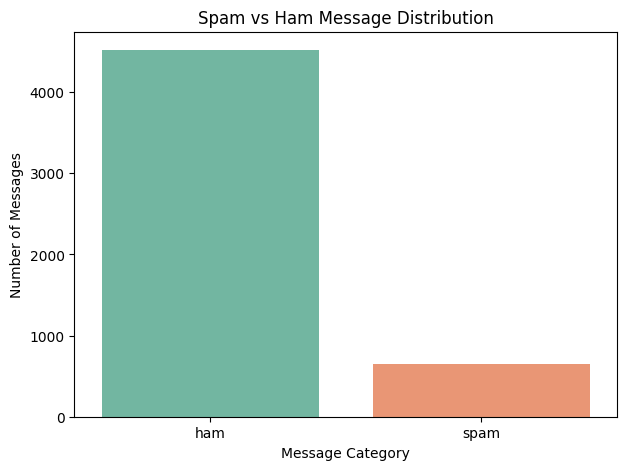

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="label",
    hue="label",
    palette="Set2",
    legend=False
)

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

**Text Preprocessing using NLP**

In [ ]:
nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

stop_words = stop_words - {"no", "not", "nor"}

stemmer = PorterStemmer()

print("NLP preprocesssing initialize successfully!")

NLP preprocesssing initialize successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


**Create Text Cleaning Function**

In [ ]:
def preprocess_text(text):

    # Convert text into lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", "", text)

    # Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Split text into words
    words = text.split()

    # Remove stopwords and perform stemming
    cleaned_words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words and len(word) > 1
    ]

    # Join words
    return " ".join(cleaned_words)


# Apply preprocessing
df["cleaned_message"] = df["message"].apply(preprocess_text)

# Display original and cleaned text
display(df[["message", "cleaned_message"]].head(10))

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi great world l...
1,Ok lar... Joking wif u oni...,ok lar joke wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,dun say earli hor alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darl week no word back like fun st...
6,Even my brother is not like to speak with me. ...,even brother not like speak treat like aid patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request mell mell oru minnaminungint nurun...
8,WINNER!! As a valued network customer you have...,winner valu network custom select receivea pri...
9,Had your mobile 11 months or more? U R entitle...,mobil month entitl updat latest colour mobil c...


**TF-IDF feature extraction**

This is one of the most important parts of the project.

Machine learning algorithms cannot directly understand text. Therefore, we convert text into numerical features using TF-IDF (Term Frequency–Inverse Document Frequency).

TF-IDF measures how important a word is in a particular document compared with the entire collection of documents.
- TF (Term Frequency): How frequently a word appears in a document.
- IDF (Inverse Document Frequency): Reduces the importance of words that appear in many documents.
The general formula is:
\[
TF-IDF(t,d)=TF(t,d)\times IDF(t)
\]

**Split the dataset**

In [ ]:
# Input features
X = df["cleaned_message"]

# Target variable
y = df["label"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4136
Testing samples: 1035


**Apply TF-IDF**

In [ ]:
# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF feature extraction completed!")

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF feature extraction completed!
Training matrix shape: (4136, 5000)
Testing matrix shape: (1035, 5000)


Train machine learning models

We will train two classifiers:
1. Multinomial Naive Bayes.
2. Logistic Regression.

**Model 1 – Multinomial Naive Bayes**

In [ ]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

print("Naive Bayes model trained Successfully!")

Naive Bayes model trained Successfully!


**Model 1 – Multinomial Naive Bayes**

In [ ]:
# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train model
lr_model.fit(X_train_tfidf, y_train)

# Predict test data
lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


**Evaluate model performance**

Accuracy



Precision



Recall



F1-score

In [ ]:
def evaluate_model(model_name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred, pos_label="spam"
    )

    recall = recall_score(
        y_true, y_pred, pos_label="spam"
    )

    f1 = f1_score(
        y_true, y_pred, pos_label="spam"
    )

    print("\n", "=" * 45)
    print("MODEL:", model_name)
    print("=" * 45)

    print("Accuracy :", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision * 100, 2), "%")
    print("Recall   :", round(recall * 100, 2), "%")
    print("F1 Score :", round(f1 * 100, 2), "%")

    print("\nClassification Report:\n")

    print(classification_report(
        y_true,
        y_pred,
        zero_division=0
    ))

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }


# Evaluate Naive Bayes
nb_results = evaluate_model(
    "Multinomial Naive Bayes",
    y_test,
    nb_predictions
)

# Evaluate Logistic Regression
lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_predictions
)


MODEL: Multinomial Naive Bayes
Accuracy : 96.62 %
Precision: 98.98 %
Recall   : 74.05 %
F1 Score : 84.72 %

Classification Report:

              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       904
        spam       0.99      0.74      0.85       131

    accuracy                           0.97      1035
   macro avg       0.98      0.87      0.91      1035
weighted avg       0.97      0.97      0.96      1035


MODEL: Logistic Regression
Accuracy : 96.81 %
Precision: 84.03 %
Recall   : 92.37 %
F1 Score : 88.0 %

Classification Report:

              precision    recall  f1-score   support

         ham       0.99      0.97      0.98       904
        spam       0.84      0.92      0.88       131

    accuracy                           0.97      1035
   macro avg       0.91      0.95      0.93      1035
weighted avg       0.97      0.97      0.97      1035



**Compare both machine learning models**

In [ ]:
# Store results
results = pd.DataFrame([
    nb_results,
    lr_results
])

print("MODEL COMPARISON")
display(results.round(4))

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Multinomial Naive Bayes,0.9662,0.9898,0.7405,0.8472
1,Logistic Regression,0.9681,0.8403,0.9237,0.8800


**Visualize model comparison**

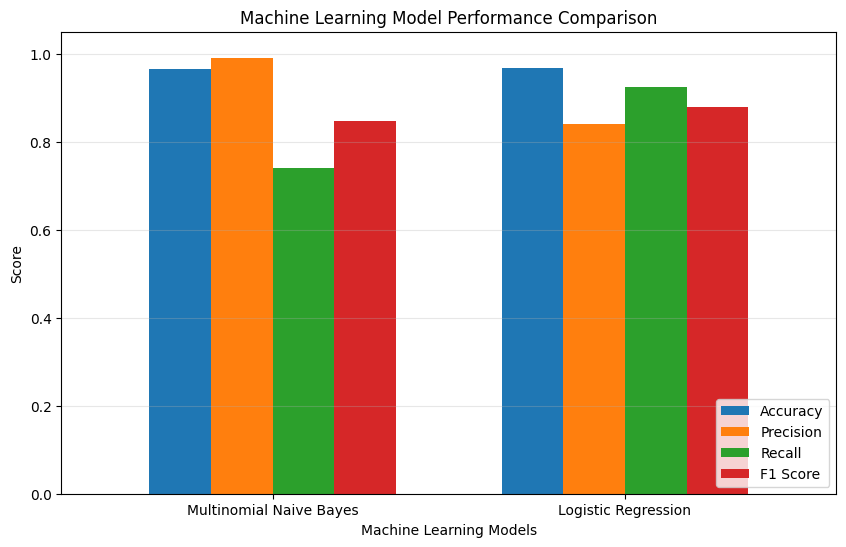

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")

plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.show()

**Confusion matrix**

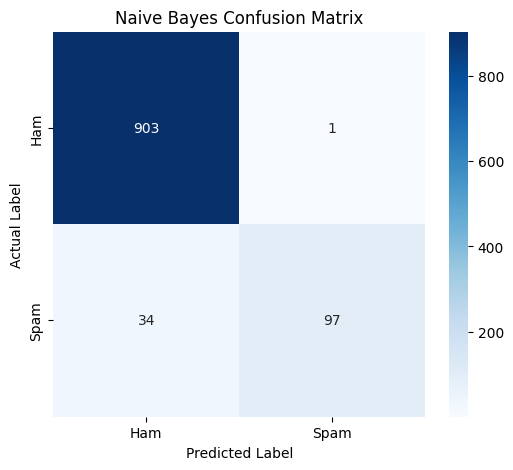

In [ ]:
cm_nb = confusion_matrix(
    y_test,
    nb_predictions,
    labels=["ham", "spam"]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

**Logistic Regression confusion matrix**

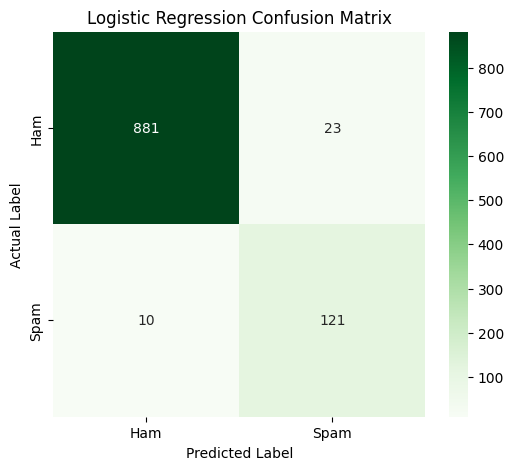

In [ ]:
cm_lr = confusion_matrix(
    y_test,
    lr_predictions,
    labels=["ham", "spam"]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

**WordCloud visualization**

WordCloud displays frequently occurring words in a visual format.

We will generate two WordClouds:
1. Spam messages.
2. Ham messages.

**Spam WordCloud**

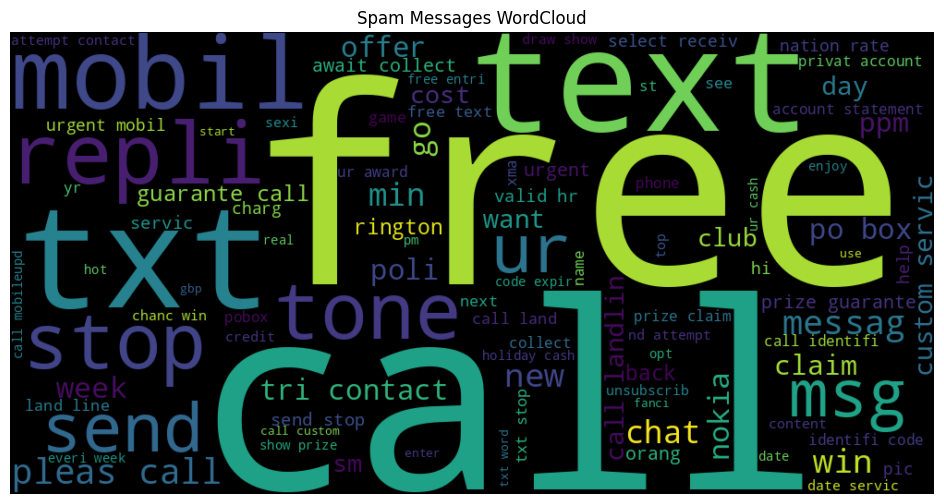

In [ ]:
# Select spam messages
spam_text = " ".join(
    df[df["label"] == "spam"]["cleaned_message"]
)

# Generate WordCloud
spam_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="black",
    max_words=100
).generate(spam_text)

# Display
plt.figure(figsize=(12, 6))

plt.imshow(
    spam_wordcloud,
    interpolation="bilinear"
)

plt.axis("off")
plt.title("Spam Messages WordCloud")

plt.show()

**Ham WordCloud**

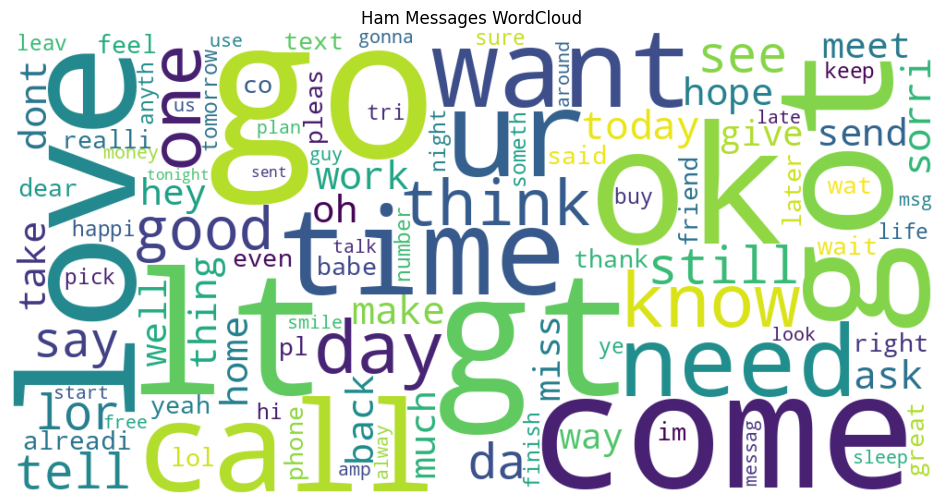

In [ ]:
# Select legitimate messages
ham_text = " ".join(
    df[df["label"] == "ham"]["cleaned_message"]
)

# Generate WordCloud
ham_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    max_words=100
).generate(ham_text)

# Display
plt.figure(figsize=(12, 6))

plt.imshow(
    ham_wordcloud,
    interpolation="bilinear"
)

plt.axis("off")
plt.title("Ham Messages WordCloud")

plt.show()

**Test the model with new messages**

In [ ]:
def predict_message(message):

    # Preprocess input
    cleaned = preprocess_text(message)

    # Convert text into TF-IDF features
    vectorized = tfidf.transform([cleaned])

    # Predict using both models
    nb_prediction = nb_model.predict(vectorized)[0]

    lr_prediction = lr_model.predict(vectorized)[0]

    print("\nOriginal Message:", message)

    print("\nNaive Bayes Prediction:", nb_prediction.upper())

    print("Logistic Regression Prediction:", lr_prediction.upper())

    return nb_prediction, lr_prediction


# Test examples
predict_message(
    "Congratulations! You have won a free cash prize. Claim now!"
)

predict_message(
    "Hey bro, are you coming to college tomorrow?"
)

predict_message(
    "URGENT! You have won a lottery. Call now to claim your reward."
)

predict_message(
    "Can you please send me the assignment notes?"
)


Original Message: Congratulations! You have won a free cash prize. Claim now!

Naive Bayes Prediction: SPAM
Logistic Regression Prediction: SPAM

Original Message: Hey bro, are you coming to college tomorrow?

Naive Bayes Prediction: HAM
Logistic Regression Prediction: HAM

Original Message: URGENT! You have won a lottery. Call now to claim your reward.

Naive Bayes Prediction: SPAM
Logistic Regression Prediction: SPAM

Original Message: Can you please send me the assignment notes?

Naive Bayes Prediction: HAM
Logistic Regression Prediction: HAM


(np.str_('ham'), 'ham')

**Save the trained model**

This step allows us to reuse our trained classifier without training it again.

In [ ]:
# Save Naive Bayes model
joblib.dump(nb_model, "spam_nb_model.pkl")

# Save Logistic Regression model
joblib.dump(lr_model, "spam_lr_model.pkl")

# Save TF-IDF vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Models saved successfully!")

Models saved successfully!


**Load saved model**

In [ ]:
# Load saved model
loaded_model = joblib.load("spam_nb_model.pkl")

# Load vectorizer
loaded_tfidf = joblib.load("tfidf_vectorizer.pkl")

# New message
new_message = "Congratulations! You won a free gift."

# Preprocess message
cleaned_message = preprocess_text(new_message)

# Transform message
message_vector = loaded_tfidf.transform([cleaned_message])

# Predict
prediction = loaded_model.predict(message_vector)

print("Message:", new_message)

print("Prediction:", prediction[0].upper())

Message: Congratulations! You won a free gift.
Prediction: HAM


# **CONCLUSION**

The Email Spam Detection project was successfully implemented using Natural Language Processing (NLP) and Machine Learning techniques. The UCI SMS Spam Collection dataset was used to train and evaluate the classification models.

Text preprocessing techniques such as lowercase conversion, punctuation removal, stopword removal, and stemming were applied to clean the textual data. TF-IDF (Term Frequency–Inverse Document Frequency) was used to convert text messages into numerical features.

Two machine learning algorithms, Multinomial Naive Bayes and Logistic Regression, were trained and evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

The Multinomial Naive Bayes model achieved an accuracy of **96.62%**, precision of **98.98%**, recall of **74.05%**, and F1-score of **84.72%**.

The Logistic Regression model achieved an accuracy of **96.81%**, precision of **84.03%**, recall of **92.37%**, and F1-score of **88.00%**.

Based on the evaluation results, Logistic Regression performed better overall, particularly in detecting spam messages. It correctly identified 121 out of 131 spam messages, whereas Multinomial Naive Bayes identified 97.

The project demonstrates that machine learning and NLP techniques can effectively classify unwanted messages and distinguish them from legitimate communication.

**Future Enhancement:** The system can be improved by using larger real-world email datasets, Support Vector Machines, advanced NLP techniques, deep learning models, and a web-based spam detection application.